# Parameter Variation Plots

1. Score (y-axis) vs. Parameter (x-axis)
2. Table 


In [1]:
from pathlib import Path

# Where job_param_variation.sh wrote its per-run output folders
main_output_folder = Path(
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_v2.0.3_param_variation"
) 

# Hi-C files (order MUST stay aligned with jet_loc_files below)
hic_files = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1b_s-23/out_fast_bounded_jets/r2.14/test1b_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/out_fast_unbounded_jets/r2.14/test1a_s-23-fast_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/out_fast_unbounded_jets/r2.14/chromsim1-fast-unbounded_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/out_fast_bounded_jets/r2.14/chromsim1-fast-bounded_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/out_slow_unbounded_jets/r2.14/test1a_s-23-slow_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1c_s-23/out_fast_bounded_jets/r2.14/test1c_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1cii_s-23/out_fast_bounded_jets/r2.14/test1cii_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1e_s-23/out_tads/r2.14/test1e_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1eii_s-23/out_tads/r2.14/test1eii_s-23_hic_003.hic",
]

# True jet locations (None = TADs, no true jets)
jet_loc_files = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1b_s-23/loading.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/narrow_loading_50.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/JET-fast-unbounded_loading_1_100.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/JET-fast-bounded_loading_1_100.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/diffuse_loading_10000.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1c_s-23/loading.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1cii_s-23/loading.csv",
    None,  # TADs
    None,  # TADs
]

# Defaults — must match DEFAULT_* in job_param_variation.sh submission
DEFAULT_Q_VAL = "0.25"
DEFAULT_RESOLUTION = 25000
DEFAULT_WINDOW_SIZE = 5000000

# Swept values — must match the *_VALS / JET_WIDTHS arrays in the submission script
# Q_VALS = [1.0, 0.5, 0.25, 0.1, 0.05, 0.01]
Q_VALS = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0]
# RESOLUTIONS  = [100000, 50000, 25000, 10000]
RESOLUTIONS  = [10000, 25000, 50000, 100000]
WINDOW_SIZES = [1000000, 2500000, 5000000, 7500000, 10000000]
# JET_WIDTHS   = [(1, 2), (2, 3), (3, 5), (5, 7.5), (7.5, 10), (10, 15),
#                 (1, 3), (2, 5), (3, 7.5), (5, 10), (7.5, 15), (1, 5), (5, 15), (1, 15)]
JET_WIDTHS = [
    (1, 2),
    (1, 3), (2, 3),
    (1, 5), (2, 5), (3, 5),
    (3, 7.5), (5, 7.5),
    (5, 10), (7.5, 10),
    (1, 15), (5, 15), (7.5, 15), (10, 15),
]

chrom = "chrS"

score_col = "f1"

In [2]:
import sys
sys.path.append('..')
import pybedtools
from utils.plotting import genomic_labels
from func_pileup import generate_bed_3

def precision_recall_f1(tp, fp, fn):
    if tp == 0 and fp == 0 and fn == 0:
        return 1.0, 1.0, 1.0
        
    precision = tp / (tp + fp) if (tp + fp) > 0 else 1.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 1.0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) > 0 else 0.0)
    return precision, recall, f1

def find_intersections(df_pred_in, df_true_in, leniency):
    """
    The df_pred must have the followign columns ['chrom', 'root', 'unique_id']

    The df_true is assumed to be the loading file given to the 3DPolyS-LE simulation,
    which has columns ['name', 'position', 'length', 'factor']. The only necessary column here is
    the 'position'
    """
    if df_pred_in.empty:
        # No predictions provided, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=0, fn=len(df_true_in) if df_true_in is not None else 0)
        result_dict = {
            "tp": 0,
            "fp": 0,
            "fn": len(df_true_in) if df_true_in is not None else 0,
            "precision": p,
            "recall": r,
            "f1": f,
            "N": 0,
        }
        return pd.DataFrame(), result_dict

    if df_true_in is None:
        # No true data provided, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=len(df_pred_in), fn=0)
        result_dict = {
            "tp": 0,
            "fp": len(df_pred_in),
            "fn": 0,
            "precision": p,
            "recall": r,
            "f1": f,
            "N": len(df_pred_in),
        }
        return pd.DataFrame(), result_dict

    df_pred = df_pred_in.copy()
    df_true = df_true_in.copy()

    

    # Need to map from genomic coordinates to bin coordiantes, which appears to 
    # differ by resolution and factor 2
    df_true["position"] /= 2 
    df_true["position"] = df_true["position"].astype(int)

    # Make BED dataframes for pybedtools intersect
    # df_pred["root"] = df_pred["root"].astype(int)
    # df_pred_bed = df_pred.assign(
    #     start=lambda d: np.clip(d["root"] - int(leniency), 0, None),
    #     end=lambda d: d["root"] + int(leniency) + 1 # half-open BED interval
    # )[["chrom", "start", "end", "unique_id", "root"]]

    df_pred_bed = df_pred[["chrom", "start", "end", "unique_id", "root"]].copy()


    chrom = df_pred["chrom"].iloc[0]
    df_true_bed = df_true.assign(
        chrom=chrom,
        start=lambda d: np.clip(d["position"] - int(leniency), 0, None),
        end=lambda d: d["position"] + int(leniency) + 1,
    )[["chrom", "start", "end", "name", "position"]]

    pred_bed = pybedtools.BedTool.from_dataframe(df_pred_bed)
    true_bed = pybedtools.BedTool.from_dataframe(df_true_bed)

    hits = pred_bed.intersect(true_bed, wa=True, wb=True)

    intersections = hits.to_dataframe(names=[
        "chrom", "pred_start", "pred_end", "unique_id", "pred_root",
        "true_chrom", "true_start", "true_end", "true_name", "true_position"
    ])

    if intersections.empty:
        print("No intersections found between predictions and true jets.")
        # No matches found, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=len(df_pred), fn=len(df_true))
        result_dict = {
            "tp": 0,
            "fp": len(df_pred),
            "fn": len(df_true),
            "precision": p,
            "recall": r,
            "f1": f,
            "N": len(df_pred),
        }
        return intersections, result_dict

    # intersections["pred_root"] = pd.to_numeric(intersections["pred_root"], errors="coerce")
    # intersections["true_position"] = pd.to_numeric(intersections["true_position"], errors="coerce")

    # --- Deduplicate: one-to-one matching by closest distance ---
    intersections["distance"] = (intersections["pred_root"] - intersections["true_position"]).abs()

    # For each true jet, keep only the closest predicted match
    intersections = intersections.sort_values("distance")
    intersections = intersections.drop_duplicates(subset="true_name", keep="first")

    # Also ensure each prediction only maps to one true jet (the closest)
    intersections = intersections.drop_duplicates(subset="unique_id", keep="first")

    # Compute scores
    matched_pred_ids = set(intersections["unique_id"].unique()) # TP
    all_pred_ids = set(df_pred["unique_id"].unique())
    matched_true_names = set(intersections["true_name"].unique()) 
    all_true_names = set(df_true["name"].unique())

    tp = len(matched_pred_ids)
    fp = len(all_pred_ids - matched_pred_ids)
    fn = len(all_true_names - matched_true_names)

    p, r, f = precision_recall_f1(tp=tp, fp=fp, fn=fn)

    result_dict = {
        "tp": tp,
        "fp" : fp,
        "fn" : fn,
        "precision": p,
        "recall": r,
        "f1": f,
        "N": len(df_pred),
    }

    return intersections, result_dict
    

In [8]:
import os
import numpy as np
import pandas as pd

from utils.plotting import genomic_labels2

# Columns for an empty summary table (missing run or no fountains called)
_EMPTY_SUMMARY_COLS = ['unique_id', 'chrom', 'start', 'end', 'length', 'input_mean',
                       'angle_mean', 'width_mean', 'jet_saliency', 'ks', 'p-val_raw',
                       'p-val_corr', 'root']

def _to_tag(value):
    """Mirror bash to_tag(): replace '.' with 'p'  (0.25 -> 0p25, 7.5 -> 7p5, 1.0 -> 1p0)."""
    return str(value).replace(".", "p")


def make_folder_name(hic_file, resolution, window_size, q_val, jet_width):
    """Per-run output folder written by job_param_variation.sh:
       {hic_base}_res{RESOLUTION}_win{WINDOW_SIZE}_q{q_tag}_{jet_width_tag}
    """
    hic_base = Path(hic_file).stem                          # basename, minus .hic
    q_tag = _to_tag(q_val)
    if jet_width is None:
        jet_width_tag = "jwdefault"
    else:
        lo, hi = jet_width
        jet_width_tag = f"jw{_to_tag(lo)}-{_to_tag(hi)}"
    return f"{hic_base}_res{resolution}_win{window_size}_q{q_tag}_{jet_width_tag}_chrS_{genomic_labels(resolution)}/{hic_base}_chrS_{genomic_labels(resolution)}_results_q_val_{q_val}"


def get_result_files_for_params(hic_file, main_output_folder, resolution, window_size, q_val, jet_width):
    """Locate summary/expanded CSVs inside the per-run folder (file naming per your example)."""
    stem = Path(hic_file).stem
    sample_name = f"{stem}_chrS_{genomic_labels(resolution)}"
    folder = Path(main_output_folder) / make_folder_name(hic_file, resolution, window_size, q_val, jet_width)
    summary_file  = str(folder / f"{sample_name}_summary_table.csv")
    expanded_file = str(folder / f"{sample_name}_expanded_table.csv")
    return summary_file, expanded_file


def compute_pooled_f1(hic_files, jet_loc_files, main_output_folder,
                      resolution, window_size, q_val, jet_width, leniency):
    """Pool TP/FP/FN across all Hi-C files for one parameter combination, then F1."""
    pool = {"tp": 0, "fp": 0, "fn": 0, "N": 0}

    for i in range(len(hic_files)):
        f_hic  = hic_files[i]
        f_true = jet_loc_files[i]
        df_true = pd.read_csv(f_true) if f_true is not None else None

        f_summary, f_expanded = get_result_files_for_params(
            f_hic, main_output_folder, resolution, window_size, q_val, jet_width
        )

        if (os.path.exists(f_expanded) and os.path.exists(f_summary)
                and pd.read_csv(f_summary, comment="#").shape[0] > 0):
            miajet_positions = pd.read_csv(f_expanded, comment="#")
            miajet_table     = pd.read_csv(f_summary,  comment="#")

            # Project to main diagonal -> root, then root ± leniency -> start/end
            miajet_table = generate_bed_3(miajet_table, miajet_positions, project_midpoint_to_diag=True)
            miajet_table["root"] = ((miajet_table["start"] + miajet_table["end"]) / 2).astype(int)
            miajet_table = generate_bed_3(miajet_table, miajet_positions, project_midpoint_to_diag=True, eps=leniency)
            miajet_table["start"] = miajet_table["start"].astype(int)
            miajet_table["end"]   = miajet_table["end"].astype(int)
            miajet_table_valid = miajet_table.copy()
        else:
            print(f"Warning: Missing or empty result files for {f_summary} ")
            miajet_table_valid = pd.DataFrame(columns=_EMPTY_SUMMARY_COLS)

        _, result_dict = find_intersections(df_pred_in=miajet_table_valid, df_true_in=df_true, leniency=leniency)
        for key in ("tp", "fp", "fn", "N"):
            pool[key] += result_dict[key]

    pool["precision"], pool["recall"], pool["f1"] = precision_recall_f1(
        tp=pool["tp"], fp=pool["fp"], fn=pool["fn"]
    )
    return pool


# Four sweeps; each holds the other three parameters at their DEFAULT_*
sweep_configs = [
    dict(name="q_val",       xlabel="q value",          values=Q_VALS,       fmt=lambda v: f"{v}"),
    dict(name="resolution",  xlabel="resolution (bp)",  values=RESOLUTIONS,  fmt=lambda v: f"{genomic_labels2(v)}"),
    dict(name="window_size", xlabel="window size (bp)", values=WINDOW_SIZES, fmt=lambda v: f"{genomic_labels2(v)}"),
    dict(name="jet_width",   xlabel="jet width",        values=JET_WIDTHS,   fmt=lambda v: f"{v[0]}-{v[1]}"),
]

def params_for(name, v):
    p = dict(resolution=DEFAULT_RESOLUTION, window_size=DEFAULT_WINDOW_SIZE,
             q_val=DEFAULT_Q_VAL, jet_width=None)
    p[name] = v
    return p

results = {}
for cfg in sweep_configs:
    f1_scores = []
    N_list = []
    for v in cfg["values"]:
        p = params_for(cfg["name"], v)
        # leniency = int(p["resolution"] * 2)   # ±2 bins; equals int(25e3*2) at the default 25 kb
        leniency = int(25e3 * 2)   # ±2 bins; equals int(25e3*2) at the default 25 kb
        pool = compute_pooled_f1(
            hic_files=hic_files, jet_loc_files=jet_loc_files,
            main_output_folder=main_output_folder, leniency=leniency, **p,
        )
        f1_scores.append(pool[score_col])
        print(f"[{cfg['name']}={cfg['fmt'](v)}] "
              f"TP={pool['tp']} FP={pool['fp']} FN={pool['fn']} | "
              f"F1={pool['f1']:.3f}  P={pool['precision']:.3f}  R={pool['recall']:.3f}")
        N_list.append(pool['N'])
    cfg["N_str"] = N_list
    results[cfg["name"]] = f1_scores
    print()

[q_val=0.01] TP=64 FP=0 FN=27 | F1=0.826  P=1.000  R=0.703
[q_val=0.05] TP=72 FP=0 FN=19 | F1=0.883  P=1.000  R=0.791
[q_val=0.1] TP=73 FP=0 FN=18 | F1=0.890  P=1.000  R=0.802
[q_val=0.25] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[q_val=0.5] TP=75 FP=7 FN=16 | F1=0.867  P=0.915  R=0.824
[q_val=1.0] TP=75 FP=18 FN=16 | F1=0.815  P=0.806  R=0.824

[resolution=10kb] TP=70 FP=2 FN=21 | F1=0.859  P=0.972  R=0.769
[resolution=25kb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[resolution=50kb] TP=60 FP=4 FN=31 | F1=0.774  P=0.938  R=0.659
[resolution=100kb] TP=54 FP=4 FN=37 | F1=0.725  P=0.931  R=0.593

[window_size=1.0Mb] TP=77 FP=3 FN=14 | F1=0.901  P=0.963  R=0.846
[window_size=2.5Mb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[window_size=5.0Mb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[window_size=7.5Mb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[window_size=10.0Mb] TP=74 FP=1 FN=17 | F1=0.892  P=0.987  R=0.813

[jet_width=1-2] TP=65 FP=8 FN=26 | F1=0.793  P=0.890  R=0

In [9]:
analysis_dir = "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_v2.0.3"

In [10]:
# import matplotlib.pyplot as plt

# for cfg in sweep_configs:
#     name = cfg["name"]
#     x_labels = [f"{cfg['fmt'](v)}\nN={cfg['N_str'][i]}" for i, v in enumerate(cfg["values"])]
#     y = results[name]
#     x_pos = range(len(y))

#     fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
#     ax.plot(x_pos, y, marker="o")

#     ax.set_xticks(list(x_pos))
#     ax.set_xticklabels(x_labels, rotation=25, ha="center", fontsize=10)

#     ax.set_xlabel(cfg["xlabel"], fontsize=14)
#     ax.set_ylabel(f"{score_col}", fontsize=14)
#     ax.set_title(
#         f"Parameter Variation '{score_col}': {cfg['xlabel']}",
#         fontsize=16
#     )

#     ax.tick_params(axis="both", labelsize=12)

#     ax.set_ylim(0.5, 1)
#     ax.grid(True, axis="y", alpha=0.3)

#     # plt.savefig(f"{analysis_dir}/param_variation_{name}_{score_col}.png", dpi=300)

#     plt.show()

In [11]:
results = {}
for cfg in sweep_configs:
    scores = {"f1": [], "precision": [], "recall": []}
    for v in cfg["values"]:
        p = params_for(cfg["name"], v)
        leniency = int(p["resolution"] * 2)
        pool = compute_pooled_f1(
            hic_files=hic_files, jet_loc_files=jet_loc_files,
            main_output_folder=main_output_folder, leniency=leniency, **p,
        )
        for m in ("f1", "precision", "recall"):
            scores[m].append(pool[m])
        print(f"[{cfg['name']}={cfg['fmt'](v)}] "
              f"TP={pool['tp']} FP={pool['fp']} FN={pool['fn']} | "
              f"F1={pool['f1']:.3f}  P={pool['precision']:.3f}  R={pool['recall']:.3f}")
    results[cfg["name"]] = scores
    print()

[q_val=0.01] TP=64 FP=0 FN=27 | F1=0.826  P=1.000  R=0.703
[q_val=0.05] TP=72 FP=0 FN=19 | F1=0.883  P=1.000  R=0.791
[q_val=0.1] TP=73 FP=0 FN=18 | F1=0.890  P=1.000  R=0.802
[q_val=0.25] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[q_val=0.5] TP=75 FP=7 FN=16 | F1=0.867  P=0.915  R=0.824
[q_val=1.0] TP=75 FP=18 FN=16 | F1=0.815  P=0.806  R=0.824

[resolution=10kb] TP=70 FP=2 FN=21 | F1=0.859  P=0.972  R=0.769
[resolution=25kb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[resolution=50kb] TP=60 FP=4 FN=31 | F1=0.774  P=0.938  R=0.659
[resolution=100kb] TP=55 FP=3 FN=36 | F1=0.738  P=0.948  R=0.604

[window_size=1.0Mb] TP=77 FP=3 FN=14 | F1=0.901  P=0.963  R=0.846
[window_size=2.5Mb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[window_size=5.0Mb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[window_size=7.5Mb] TP=75 FP=1 FN=16 | F1=0.898  P=0.987  R=0.824
[window_size=10.0Mb] TP=74 FP=1 FN=17 | F1=0.892  P=0.987  R=0.813

[jet_width=1-2] TP=65 FP=8 FN=26 | F1=0.793  P=0.890  R=0

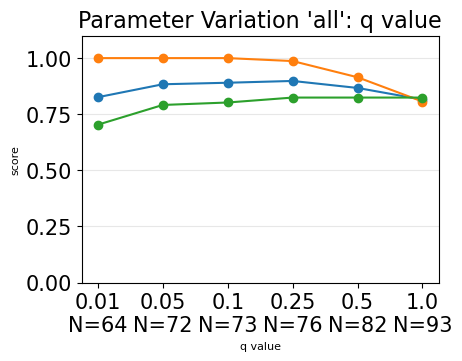

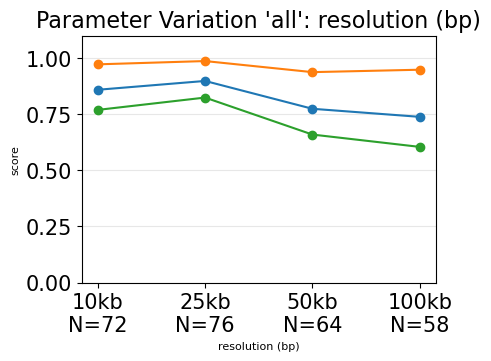

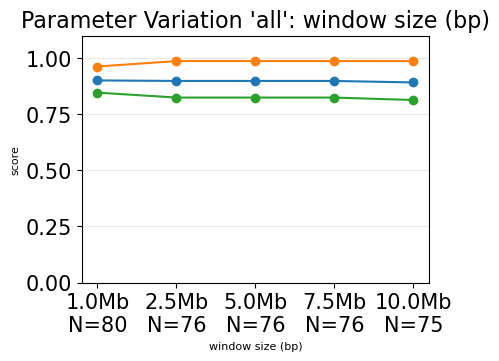

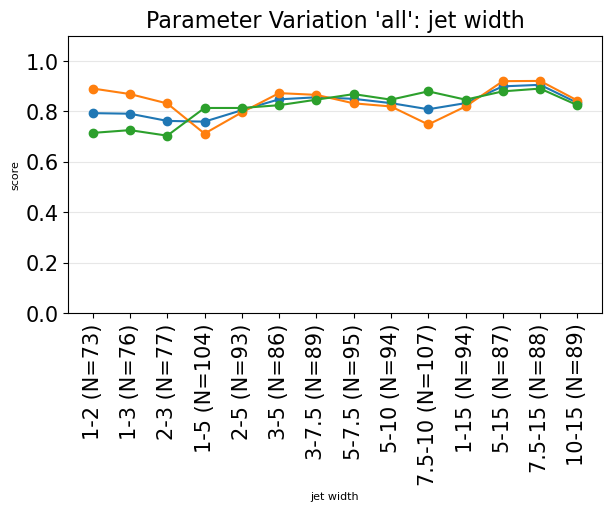

In [12]:
import matplotlib.pyplot as plt

for cfg in sweep_configs:
    name = cfg["name"]
    scores = results[name]

    if name == "jet_width":
        figsize = (6, 5)
        x_labels = [f"{cfg['fmt'](v)} (N={cfg['N_str'][i]})" for i, v in enumerate(cfg["values"])]
    else:
        figsize = (4.5, 3.5)
        x_labels = [f"{cfg['fmt'](v)}\nN={cfg['N_str'][i]}" for i, v in enumerate(cfg["values"])]
    x_pos = range(len(x_labels))

    fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    for m in ("f1", "precision", "recall"):
        ax.plot(x_pos, scores[m], marker="o", label=m)

    ax.set_xticks(list(x_pos))
    if name == "jet_width":
        ax.set_xticklabels(x_labels, rotation=90, ha="center", fontsize=15)
    else:
        ax.set_xticklabels(x_labels, rotation=0, ha="center", fontsize=15)

    ax.set_xlabel(cfg["xlabel"], fontsize=8)
    ax.set_ylabel("score", fontsize=8)
    ax.set_title(
        f"Parameter Variation 'all': {cfg['xlabel']}",
        fontsize=16
    )

    ax.tick_params(axis="both", labelsize=15)

    ax.set_ylim(0, 1.1)
    ax.grid(True, axis="y", alpha=0.3)
    # ax.legend(fontsize=12.5)

    # plt.savefig(f"{analysis_dir}/param_variation_{name}_all.png", dpi=300, bbox_inches="tight")
    plt.show()
    